In [1]:
import pandas as pd

df = pd.read_csv('/content/sample-marketing.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

Dataset loaded successfully!
Dataset shape: (260, 8)
Columns: ['date', 'channel', 'campaign', 'impressions', 'clicks', 'spend', 'conversions', 'revenue']


,date,channel,campaign,impressions,clicks,spend,conversions,revenue
0,2026-02-24,Organic,Brand-9,24549,1392,1698.24,45,4632.75
1,2026-01-23,Organic,Brand-1,49123,2235,4559.40,40,3373.60
2,2026-03-02,Email,Spring-4,83777,1215,1518.75,105,12655.65
3,2026-01-08,Organic,Retargeting-6,9714,445,1388.40,30,3683.40
4,2026-02-21,Email,Brand-6,45743,2594,5473.34,154,32731.16


In [9]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

Missing values:
date                   0
channel                0
campaign               0
impressions            0
clicks                 0
spend                  0
conversions            0
revenue                0
CTR_pct                0
Conversion_Rate_pct    0
Cost_Per_Click         0
ROI_pct                0
dtype: int64

Duplicate rows: 0

Data types:
date                   datetime64[ns]
channel                        object
campaign                       object
impressions                     int64
clicks                          int64
spend                         float64
conversions                     int64
revenue                       float64
CTR_pct                       float64
Conversion_Rate_pct           float64
Cost_Per_Click                float64
ROI_pct                       float64
dtype: object


In [10]:
df['date'] = pd.to_datetime(df['date'], errors='coerce')

print("Date column converted!")
print("Date data type:", df['date'].dtype)
print("Invalid dates:", df['date'].isna().sum())

Date column converted!
Date data type: datetime64[ns]
Invalid dates: 0


In [11]:
import numpy as np

# Click-through rate (%)
df['CTR_pct'] = np.where(
    df['impressions'] > 0,
    df['clicks'] / df['impressions'] * 100,
    np.nan
)

# Conversion rate (%)
df['Conversion_Rate_pct'] = np.where(
    df['clicks'] > 0,
    df['conversions'] / df['clicks'] * 100,
    np.nan
)

# Cost per click
df['Cost_Per_Click'] = np.where(
    df['clicks'] > 0,
    df['spend'] / df['clicks'],
    np.nan
)

# Return on investment (%)
df['ROI_pct'] = np.where(
    df['spend'] > 0,
    (df['revenue'] - df['spend']) / df['spend'] * 100,
    np.nan
)

print("Marketing metrics calculated successfully!")

display(df[['channel', 'impressions', 'clicks',
            'conversions', 'spend', 'revenue',
            'CTR_pct', 'Conversion_Rate_pct',
            'Cost_Per_Click', 'ROI_pct']].head())

Marketing metrics calculated successfully!


,channel,impressions,clicks,conversions,spend,revenue,CTR_pct,Conversion_Rate_pct,Cost_Per_Click,ROI_pct
0,Organic,24549,1392,45,1698.24,4632.75,5.670292,3.232759,1.22,172.797131
1,Organic,49123,2235,40,4559.40,3373.60,4.549804,1.789709,2.04,-26.007808
2,Email,83777,1215,105,1518.75,12655.65,1.450279,8.641975,1.25,733.293827
3,Organic,9714,445,30,1388.40,3683.40,4.581017,6.741573,3.12,165.298185
4,Email,45743,2594,154,5473.34,32731.16,5.670813,5.936777,2.11,498.010721


In [12]:
# Summarize total performance for each marketing channel
channel_summary = df.groupby('channel', as_index=False).agg(
    impressions=('impressions', 'sum'),
    clicks=('clicks', 'sum'),
    conversions=('conversions', 'sum'),
    spend=('spend', 'sum'),
    revenue=('revenue', 'sum')
)

# Calculate channel-level performance metrics
channel_summary['CTR_pct'] = (
    channel_summary['clicks'] / channel_summary['impressions'] * 100
)

channel_summary['Conversion_Rate_pct'] = (
    channel_summary['conversions'] / channel_summary['clicks'] * 100
)

channel_summary['Cost_Per_Click'] = (
    channel_summary['spend'] / channel_summary['clicks']
)

channel_summary['ROI_pct'] = (
    (channel_summary['revenue'] - channel_summary['spend'])
    / channel_summary['spend'] * 100
)

# Show highest-ROI channels first
channel_summary = channel_summary.sort_values(
    'ROI_pct', ascending=False
)

display(channel_summary.round(2))

,channel,impressions,clicks,conversions,spend,revenue,CTR_pct,Conversion_Rate_pct,Cost_Per_Click,ROI_pct
4,Meta Ads,1088701,36388,3098,65394.72,412845.02,3.34,8.51,1.80,531.31
3,LinkedIn,2166529,77931,4832,128423.06,665081.15,3.60,6.20,1.65,417.88
0,Affiliate,1227654,41980,3091,90296.74,425789.82,3.42,7.36,2.15,371.55
5,Organic,1757541,65060,4169,111037.12,426282.41,3.70,6.41,1.71,283.91
1,Email,1968601,66649,3896,139415.51,509426.90,3.39,5.85,2.09,265.40
2,Google Ads,1621491,50683,3498,98350.33,350750.79,3.13,6.90,1.94,256.63
6,TikTok,1794038,55477,2838,99352.40,338118.51,3.09,5.12,1.79,240.32


In [13]:
import plotly.graph_objects as go

# Calculate total funnel numbers
total_impressions = int(df['impressions'].sum())
total_clicks = int(df['clicks'].sum())
total_conversions = int(df['conversions'].sum())

fig = go.Figure(go.Funnel(
    y=['Impressions', 'Clicks', 'Conversions'],
    x=[total_impressions, total_clicks, total_conversions],
    textinfo='value+percent initial'
))

fig.update_layout(
    title='Marketing Campaign Conversion Funnel',
    template='plotly_white'
)

fig.show()

print("Total Impressions:", f"{total_impressions:,}")
print("Total Clicks:", f"{total_clicks:,}")
print("Total Conversions:", f"{total_conversions:,}")

Total Impressions: 11,624,555
Total Clicks: 394,168
Total Conversions: 25,422


In [18]:
# Prepare funnel values
funnel_labels = ['Impressions', 'Clicks', 'Conversions']
funnel_values = [
    total_impressions,
    total_clicks,
    total_conversions
]

# Calculate percentage of initial impressions
funnel_percentages = [
    100,
    total_clicks / total_impressions * 100,
    total_conversions / total_impressions * 100
]

# Display exact values and percentages
funnel_text = [
    f"{value:,}<br>{pct:.2f}% of impressions"
    for value, pct in zip(funnel_values, funnel_percentages)
]

fig = go.Figure(go.Funnel(
    y=funnel_labels,
    x=funnel_values,
    text=funnel_text,
    textinfo='text',
    textposition='outside'
))

fig.update_layout(
    title='Marketing Campaign Conversion Funnel',
    template='plotly_white'
)

fig.show()

print(f"Click-through rate: {total_clicks / total_impressions * 100:.2f}%")
print(f"Conversion rate from clicks: {total_conversions / total_clicks * 100:.2f}%")
print(f"Overall conversion rate: {total_conversions / total_impressions * 100:.2f}%")

Click-through rate: 3.39%
Conversion rate from clicks: 6.45%
Overall conversion rate: 0.22%


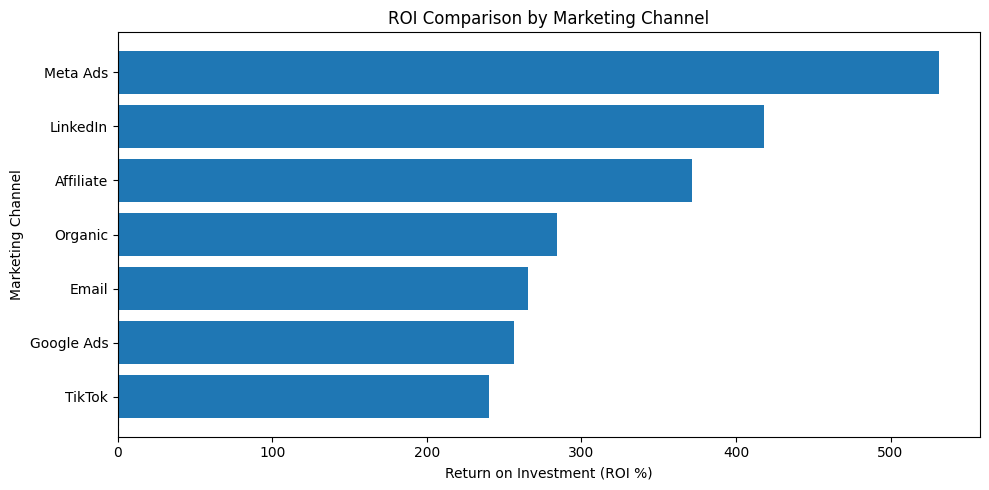

In [21]:
import matplotlib.pyplot as plt

# Sort channels by ROI
roi_chart = channel_summary.sort_values('ROI_pct')

plt.figure(figsize=(10, 5))
plt.barh(roi_chart['channel'], roi_chart['ROI_pct'])
plt.axvline(0, linestyle='--')
plt.xlabel('Return on Investment (ROI %)')
plt.ylabel('Marketing Channel')
plt.title('ROI Comparison by Marketing Channel')
plt.tight_layout()
plt.show()

In [16]:
df.to_csv('/content/Marketing_Campaign_Cleaned.csv', index=False)

print("Cleaned marketing dataset exported successfully!")
print("Rows and columns:", df.shape)

Cleaned marketing dataset exported successfully!
Rows and columns: (260, 12)


In [19]:
fig.update_layout(
    title='Marketing Campaign Conversion Funnel',
    template='plotly_white',
    margin=dict(l=100, r=220, t=80, b=60)
)

In [20]:
import plotly.graph_objects as go

funnel_values = [
    total_impressions,
    total_clicks,
    total_conversions
]

funnel_text = [
    f"{total_impressions / 1_000_000:.2f}M<br>100.00%",
    f"{total_clicks / 1_000:.2f}K<br>{total_clicks / total_impressions * 100:.2f}%",
    f"{total_conversions / 1_000:.2f}K<br>{total_conversions / total_impressions * 100:.2f}%"
]

fig = go.Figure(go.Funnel(
    y=['Impressions', 'Clicks', 'Conversions'],
    x=funnel_values,
    text=funnel_text,
    textinfo='text',
    textposition='outside'
))

fig.update_layout(
    title='Marketing Campaign Conversion Funnel',
    template='plotly_white',
    width=1150,
    height=600,
    margin=dict(l=100, r=320, t=80, b=60)
)

fig.show()

print(f"Total Impressions: {total_impressions:,}")
print(f"Total Clicks: {total_clicks:,}")
print(f"Total Conversions: {total_conversions:,}")
print(f"Click-through rate: {total_clicks / total_impressions * 100:.2f}%")
print(f"Conversion rate from clicks: {total_conversions / total_clicks * 100:.2f}%")
print(f"Overall conversion rate: {total_conversions / total_impressions * 100:.2f}%")

Total Impressions: 11,624,555
Total Clicks: 394,168
Total Conversions: 25,422
Click-through rate: 3.39%
Conversion rate from clicks: 6.45%
Overall conversion rate: 0.22%
